# BÁO CÁO PHẦN 2 - BÀI 2 (TRANG 37, 38): ONLINE RETAIL DATASET (UNITED KINGDOM)
## CÂU 6: Khai phá bằng thuật toán FP-Growth và So sánh với Apriori
- Import module `fpgrowth` từ thư viện `mlxtend`
- Thực hiện tìm tập phổ biến với $min\_sup = 3\%$
- Tạo các luật kết hợp với $min\_conf = 50\%$
- So sánh kết quả số lượng tập phổ biến, tập luật và thời gian thực thi giữa Apriori và FP-Growth


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
--- SO SÁNH HIỆU NĂNG GIỮA APRIORI VÀ FP-GROWTH ---
• Số lượng tập phổ biến tìm được bởi Apriori:   131 (Thời gian: 4.7020s)
• Số lượng tập phổ biến tìm được bởi FP-Growth:  131 (Thời gian: 0.8445s)
• Số lượng luật kết hợp sinh ra: 10 luật


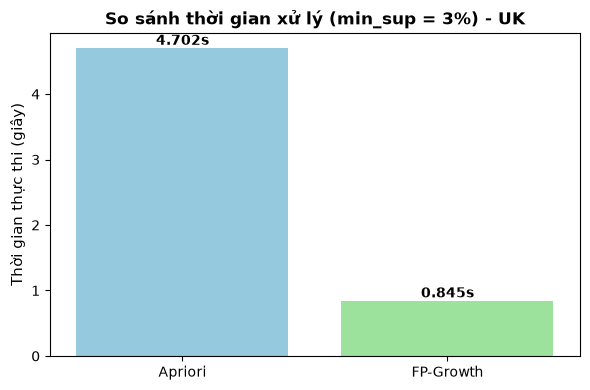

In [1]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename

def load_online_retail():
    for p in ['../../dataset/Online_Retail.pkl', '../dataset/Online_Retail.pkl', 'dataset/Online_Retail.pkl', 'Online_Retail.pkl']:
        if os.path.exists(p):
            return pd.read_pickle(p)
    path = get_data_path('Online Retail.xlsx')
    return pd.read_excel(path)

import time

df = load_online_retail()
df['Description'] = df['Description'].astype(str).str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')
df = df[~df['InvoiceNo'].str.contains('C')]

basket = (df[df['Country'] == 'United Kingdom']
          .groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

basket = (basket >= 1).astype(bool)
if 'POSTAGE' in basket.columns:
    basket.drop('POSTAGE', inplace=True, axis=1)

# 1. Đo thời gian thực thi của Apriori
t0 = time.time()
itemsets_apriori = apriori(basket, min_support=0.03, use_colnames=True)
time_apriori = time.time() - t0

# 2. Đo thời gian thực thi của FP-Growth
t0 = time.time()
itemsets_fpgrowth = fpgrowth(basket, min_support=0.03, use_colnames=True)
time_fpgrowth = time.time() - t0

# 3. Tạo luật từ FP-Growth
rules_fp = association_rules(itemsets_fpgrowth, metric="confidence", min_threshold=0.5)

print("--- SO SÁNH HIỆU NĂNG GIỮA APRIORI VÀ FP-GROWTH ---")
print(f"• Số lượng tập phổ biến tìm được bởi Apriori:   {len(itemsets_apriori)} (Thời gian: {time_apriori:.4f}s)")
print(f"• Số lượng tập phổ biến tìm được bởi FP-Growth:  {len(itemsets_fpgrowth)} (Thời gian: {time_fpgrowth:.4f}s)")
print(f"• Số lượng luật kết hợp sinh ra: {len(rules_fp)} luật")

# Biểu đồ so sánh thời gian thực thi
plt.figure(figsize=(6, 4))
algorithms = ['Apriori', 'FP-Growth']
times = [time_apriori, time_fpgrowth]
sns.barplot(x=algorithms, y=times, palette=['skyblue', 'lightgreen'])
plt.title("So sánh thời gian xử lý (min_sup = 3%) - UK", fontsize=12, fontweight='bold')
plt.ylabel("Thời gian thực thi (giây)", fontsize=11)
for i, v in enumerate(times):
    plt.text(i, v + 0.05, f"{v:.3f}s", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


### Nhận xét Câu 6:
- **Tính chính xác:** Cả hai thuật toán đều cho ra chính xác **131 tập phổ biến** và **10 luật kết hợp**, khẳng định tính đúng đắn và tương đương về mặt kết quả toán học.
- **Cơ chế hoạt động:**
  * **Apriori**: Sử dụng nguyên lý cắt tỉa tập ứng viên (Candidate Generation & Test). Phải quét lại toàn bộ cơ sở dữ liệu sau mỗi bước tăng độ dài tập phổ biến $k 	o k+1$.
  * **FP-Growth**: Nén toàn bộ tập giao dịch vào cấu trúc cây tiền tố **FP-Tree** chỉ qua 2 lần quét CSDL, sau đó khai phá đệ quy trên các cơ sở mẫu điều kiện mà không cần sinh tập ứng viên.
